In [14]:
import polars as pl
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import numpy.typing as npt
import utils

EXPORT_DATA = True


In [ ]:

df = pl.read_csv("../data/alibaba-2020/generated/merged_dataframes.csv")

df.head()

In [2]:
def calc_cpu_power_virtual(
    *, utilization: npt.ArrayLike, n: npt.ArrayLike, N: npt.ArrayLike
) -> npt.NDArray[np.float32]:
    """calculates CPU power based on https://sci-hub.st/10.1007/s00500-016-2154-6

    data transformation is needed due to the difference between article's utilization concept
    and dataset utilization.

    This method has THE FOLLOWING PROBLEMS:
    - This method assumes full virtualization, unlike Kubernetes pods.
    While n (CPU cores) is predefined in full virtualization, it's unknown in Kubernetes and it has to be assumed.
    Which will result in errors.
    - This method is the tested server only has 16 cores,
    servers in our dataset have up to 96 cores, which also can lead to error
    - The article is old

    Args:
        utilization (npt.ArrayLike): utilization of the  cpu where each cores maximum utilization is 100, for example 300 means 3 cores full utilization
        n (npt.ArrayLike): number of virtualized cores
        N (npt.ArrayLike): number of total cores

    Returns:
        npt.NDArray[np.float32]: power consumptions in watts
    """

    utilization_frac = np.array(utilization) / 100.0
    n = np.array(n)
    N = np.array(N)

    u_v = utilization_frac / n
    pw = np.array(13.114 * (n / N) ** 0.609 * u_v**0.609, dtype=np.float32)
    return pw

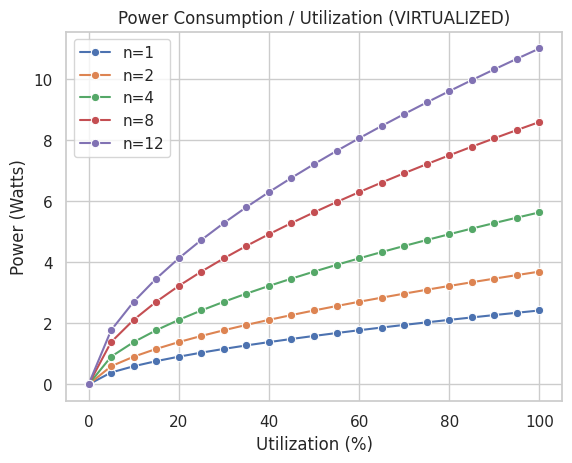

In [3]:
# VALIDATION based on https://sci-hub.st/10.1007/s00500-016-2154-6
# the plots are the same
# through trial and error N is found to be around 16

sns.set_theme(style="whitegrid")

utilization_percents = np.arange(0.0, 105, 5)
ns = [1, 2, 4, 8, 12]
N = 16

for n in ns:
    powers = calc_cpu_power_virtual(utilization=n * utilization_percents, n=n, N=N)
    sns.lineplot(y=powers, x=utilization_percents, label=f"n={n}", marker="o")
    plt.title("Power Consumption / Utilization (VIRTUALIZED)")
    plt.xlabel("Utilization (%)")
    plt.ylabel("Power (Watts)")

In [4]:
def calc_cpu_power_linear(
    *, c: npt.ArrayLike, utilization: npt.ArrayLike
) -> npt.NDArray[np.float32]:
    """calculates SINGLE CORE'S power consumption based on https://ieeexplore.ieee.org/document/6846513
    the data has to be transformed since article's idea of utilization is different from our dataset
    This method has the FOLLOWING PROBLEMS:
    - C_cpu is unknown for k8s pods and it has to be assumed
    - article is old

    Args:
        c (npt.ArrayLike): number of active cores
        utilization (npt.ArrayLike): utilization of each active core

    Returns:
        npt.NDArray[np.float32]: SINGLE CORE'S power consumption in watts
    """

    utilization_frac = np.array(utilization)
    c = np.array(c)
    u_cpu = utilization_frac / c

    C_cpu = 0.016 * (c**2) - 0.112 * c + 0.414
    return u_cpu * C_cpu

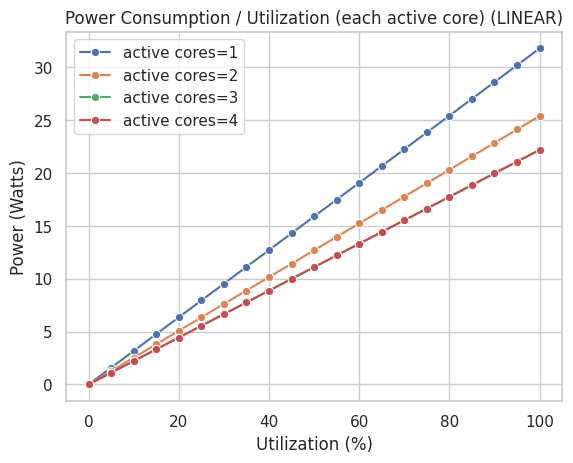

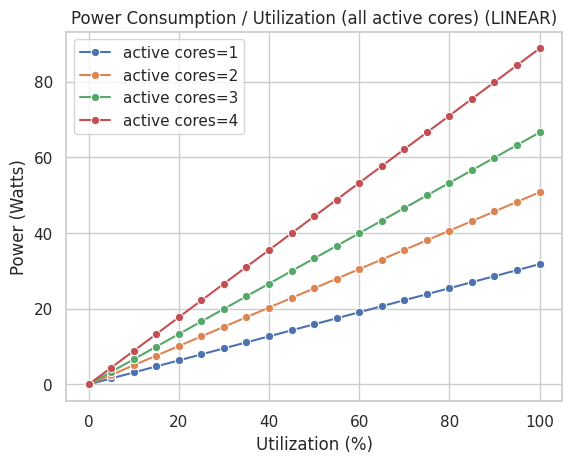

In [5]:
# VALIDATION of the linear power model
# The plot matches the reference plot in the article
# 3 active cores is not visible because the value to is too close 4 active cores

active_cores = np.arange(1, 5, 1)
utilization_percents = np.arange(0.0, 105, 5)

for c in active_cores:
    powers: np.ndarray = calc_cpu_power_linear(
        c=c, utilization=c * utilization_percents
    )
    sns.lineplot(
        y=powers, x=utilization_percents, label=f"active cores={c}", marker="o"
    )
    plt.title("Power Consumption / Utilization (each active core) (LINEAR)")
    plt.xlabel("Utilization (%)")
    plt.ylabel("Power (Watts)")
plt.show()

for c in active_cores:
    powers: np.ndarray = calc_cpu_power_linear(
        c=c, utilization=c * utilization_percents
    )
    sns.lineplot(
        y=c * powers, x=utilization_percents, label=f"active cores={c}", marker="o"
    )
    plt.title("Power Consumption / Utilization (all active cores) (LINEAR)")
    plt.xlabel("Utilization (%)")
    plt.ylabel("Power (Watts)")
plt.show()

In [6]:
df = df[["start_time", "end_time", "machine_cpu"]]
df

start_time,end_time,machine_cpu
i64,i64,f64
2134401,2134599,null
2806218,2806331,49.391271
3084090,3084411,50.949074
2119980,2134354,null
2164803,2171278,null
…,…,…
5071473,5072751,null
5587389,5588781,null
6047942,6082786,null


In [7]:
df = df.drop_nulls(["machine_cpu"])
df

start_time,end_time,machine_cpu
i64,i64,f64
2806218,2806331,49.391271
3084090,3084411,50.949074
2659273,2673034,38.279293
2660994,2674496,36.739657
2826419,2834615,45.814088
…,…,…
6400720,6400991,18.326933
6400720,6400992,18.326933
6400720,6401002,18.326933


In [8]:
# giving tasks with more than 0.45 utilization 2 cores and 1 core to tasks less than that
df = df.with_columns(
    pl.col("machine_cpu")
    .mul(1 / 100)
    .add(0.55)
    .round()
    .alias("active_cores")
    .cast(pl.Int16)
)
df = df.with_columns(
    pl.col("machine_cpu").mul(1 / pl.col("active_cores")).alias("utilization_per_core")
)


df

start_time,end_time,machine_cpu,active_cores,utilization_per_core
i64,i64,f64,i16,f64
2806218,2806331,49.391271,1,49.391271
3084090,3084411,50.949074,1,50.949074
2659273,2673034,38.279293,1,38.279293
2660994,2674496,36.739657,1,36.739657
2826419,2834615,45.814088,1,45.814088
…,…,…,…,…
6400720,6400991,18.326933,1,18.326933
6400720,6400992,18.326933,1,18.326933
6400720,6401002,18.326933,1,18.326933


In [9]:
cpu_power_per_core = calc_cpu_power_linear(
    c=df["active_cores"], utilization=df["utilization_per_core"]
)
df = df.with_columns(
    pl.col("active_cores").mul(cpu_power_per_core).alias("power_watts")
)
df

start_time,end_time,machine_cpu,active_cores,utilization_per_core,power_watts
i64,i64,f64,i16,f64,f64
2806218,2806331,49.391271,1,49.391271,15.706424
3084090,3084411,50.949074,1,50.949074,16.201805
2659273,2673034,38.279293,1,38.279293,12.172815
2660994,2674496,36.739657,1,36.739657,11.683211
2826419,2834615,45.814088,1,45.814088,14.56888
…,…,…,…,…,…
6400720,6400991,18.326933,1,18.326933,5.827965
6400720,6400992,18.326933,1,18.326933,5.827965
6400720,6401002,18.326933,1,18.326933,5.827965


In [10]:
df.group_by("active_cores").len()

active_cores,len
i16,u32
1,882130
2,1398


In [11]:
df = utils.reset_start_to_zero(df, cols=["start_time", "end_time"])
df = utils.add_min_cols(df, cols=["start_time", "end_time"])
df

start_time,end_time,machine_cpu,active_cores,utilization_per_core,power_watts,start_time_min,end_time_min
i64,i64,f64,i16,f64,f64,i64,i64
792322,792435,49.391271,1,49.391271,15.706424,13205,13207
1070194,1070515,50.949074,1,50.949074,16.201805,17837,17842
645377,659138,38.279293,1,38.279293,12.172815,10756,10986
647098,660600,36.739657,1,36.739657,11.683211,10785,11010
812523,820719,45.814088,1,45.814088,14.56888,13542,13679
…,…,…,…,…,…,…,…
4386824,4387095,18.326933,1,18.326933,5.827965,73114,73118
4386824,4387096,18.326933,1,18.326933,5.827965,73114,73118
4386824,4387106,18.326933,1,18.326933,5.827965,73114,73118


In [12]:
ts = utils.make_ts(df, value_col="power_watts")
ts

time,power_watts,power_watts_right,diff,diff_cum
i64,f64,f64,f64,f64
0,3.535193,0.0,3.535193,3.535193
2048,29.201065,0.0,29.201065,32.736258
2079,42.253149,0.0,42.253149,74.989406
2095,2.624895,0.0,2.624895,77.614302
2542,11.35918,0.0,11.35918,88.973482
…,…,…,…,…
73951,0.0,-103.860408,-103.860408,166.422279
73952,7.800896,-48.905779,-41.104882,125.317397
73953,0.0,-69.552315,-69.552315,55.765081


Text(0, 0.5, 'CPU Power (Watts)')

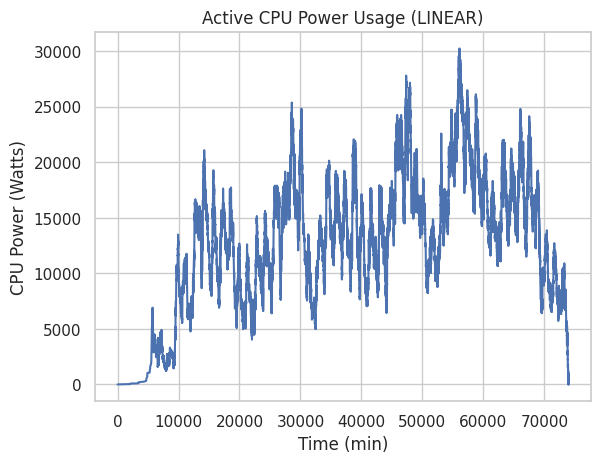

In [13]:
sns.set_theme(style="whitegrid")
sns.lineplot(x=ts["time"], y=ts["diff_cum"])
plt.title("Active CPU Power Usage (LINEAR)")
plt.xlabel("Time (min)")
plt.ylabel("CPU Power (Watts)")

In [15]:
if EXPORT_DATA:
  ts_csv = ts[['time', 'diff_cum']]
  ts_csv = ts_csv.rename({'diff_cum': 'power'})
  ts_csv.write_csv('../data/alibaba-2020/generated/cpu_active_power_min.csv')

In [14]:
ts_hourly = utils.minly_to_hourly(ts, time_col="time")
ts_hourly

time_hourly,power_watts,power_watts_right,diff,diff_cum
f64,f64,f64,f64,f64
599.0,174.291442,-160.523193,13.768249,15521.189516
458.0,157.295597,-160.041699,-2.746102,17297.540859
978.0,262.337334,-205.904004,56.43333,21370.718556
138.0,40.087093,-29.852194,10.2349,2189.211977
254.0,65.822914,-48.668571,17.154343,8990.492213
…,…,…,…,…
525.0,96.709162,-102.289178,-5.580016,10963.026686
136.0,30.485542,-33.053573,-2.568032,1915.337493
410.0,161.828221,-173.008705,-11.180484,12250.212455


Text(0, 0.5, 'CPU Power (Watts)')

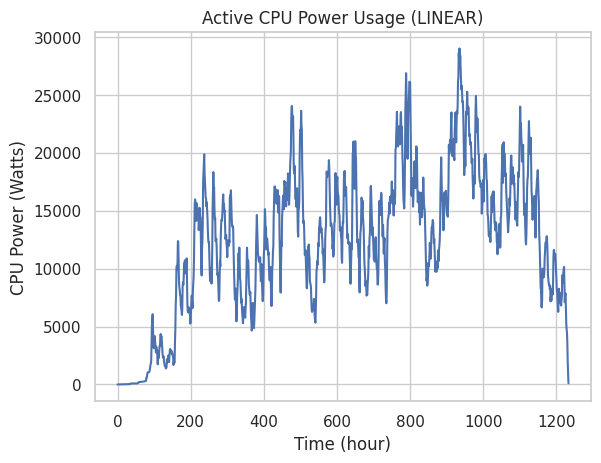

In [17]:
sns.set_theme(style="whitegrid")
sns.lineplot(x=ts_hourly["time_hourly"], y=ts_hourly["diff_cum"])
plt.title("Active CPU Power Usage (LINEAR)")
plt.xlabel("Time (hour)")
plt.ylabel("CPU Power (Watts)")